In [141]:
import numpy as np
import re
import math
import sys
from collections import defaultdict, Counter
import json
import itertools
import warnings
import statistics
from pathlib import Path
import zipfile
from scipy import interpolate
from matplotlib import pyplot as plt
%matplotlib inline

In [142]:
def notebook_path_on_disk():
    return Path(json.loads(Path(sys.argv[-1]).read_bytes())['jupyter_session'])

modification_data = {
    'short_across_traces': [31, 32, 33, 34, 35],
    'short_within_trace': [26, 27, 28, 29, 30],
    'open': [21, 22, 23, 24, 25],
}

def load_multichannel_data(path=None):
    if path is None:
        # Get the data dir independent on where exactly the Jupyter server is running
        path = notebook_path_on_disk().parent.parent / 'data_multi'
        
    data_dict = defaultdict(list)
    for le_zip in path.glob('*.zip'):
        le_zip = zipfile.ZipFile(le_zip)
        for entry in le_zip.infolist():
            if not entry.filename.endswith('.json'):
                continue
            data = json.loads(le_zip.read(entry))
            info = data['info']
            meta, specimen = info['meta'], info['specimen']
            mesh_id = specimen
            _rest, _, serial = specimen.rpartition('-')
            try:
                serial = int(serial)
            except:
                serial = 'none'

            mods = []
            for modification, matching_serials in modification_data.items():
                if serial in matching_serials:
                    mods.append(modification)
            info['mods'] = mods

            if (g := re.search(r'p([.0-9]+)', meta)):
                pitch = str(float(*g.groups()))
            else:
                warnings.warn(f'Unknown pitch for {meta!r}')
                pitch = '?'

            mesh_layout = re.sub(r'-\d{4}', '', specimen)
            
            if (g := re.search(r'side-([ab])-(right|left)', meta)):
                layer, half = g.groups()
                mesh_id = f'M-{specimen}-{pitch}-{layer}-{half}'
                mesh_layout += f'-{layer}-{half}'
            else:
                mesh_id = f'M-{specimen}-{pitch}'
            info['mesh_id'] = mesh_id
            info['mesh_layout'] = mesh_layout
            info['pitch'] = pitch
            info['serial'] = serial if serial != 'none' else 0
            data_dict[mesh_id].append(data)
    return data_dict

data = load_multichannel_data()

/tmp/ipykernel_784132/2647136726.py:40: UserWarning: Unknown pitch for 'baseline-5-open'
  warnings.warn(f'Unknown pitch for {meta!r}')


In [143]:
{key: value[0]['info'].get('mods') for key, value in data.items()}

{'M-SP-PITCH-V2-0100-0.3': [],
 'M-SP-PITCH-V2-0097-0.3': [],
 'M-SP-PITCH-V2-0096-0.3': [],
 'M-SP-PITCH-V2-0099-0.3': [],
 'M-SP-PITCH-V2-0098-0.3': [],
 'M-SP-PITCH-V2-0095-0.3': [],
 'M-SP-PITCH-V2-0094-0.3': [],
 'M-SP-PITCH-V2-0093-0.3': [],
 'M-SP-PITCH-V2-0092-0.3': [],
 'M-SP-PITCH-V2-0091-0.3': [],
 'M-SP-PITCH-V2-0090-0.3': [],
 'M-SP-PITCH-V2-0089-0.3': [],
 'M-SP-PITCH-V2-0088-0.3': [],
 'M-SP-PITCH-V2-0087-0.3': [],
 'M-SP-PITCH-V2-0086-0.3': [],
 'M-SP-PITCH-V2-0085-0.3': [],
 'M-SP-PITCH-V2-0084-0.3': [],
 'M-SP-PITCH-V2-0083-0.3': [],
 'M-SP-PITCH-V2-0082-0.3': [],
 'M-SP-PITCH-V2-0081-0.3': [],
 'M-SP-PITCH-V2-0080-0.3': [],
 'M-SP-PITCH-V2-0079-0.3': [],
 'M-SP-PITCH-V2-0078-0.3': [],
 'M-SP-PITCH-V2-0077-0.3': [],
 'M-SP-PITCH-V2-0076-0.3': [],
 'M-SP-PITCH-V2-0075-0.3': [],
 'M-SP-PITCH-V2-0074-0.3': [],
 'M-SP-PITCH-V2-0073-0.3': [],
 'M-SP-PITCH-V2-0072-0.3': [],
 'M-SP-PITCH-V2-0071-0.3': [],
 'M-SP-PITCH-V2-0070-0.3': [],
 'M-SP-PITCH-V2-0069-0.3': [],
 'M-SP-P

In [144]:
Counter([value['info']['meta'] for entries in data.values() for value in entries])

Counter({'Baseline-2-p0.3': 100,
         'Baseline-1-p0.3': 30,
         'Baseline-2-p0.4': 30,
         'Baseline-1-p0.4': 25,
         'mods-25-07-01-01-p0.3': 16,
         'mods-25-07-01-01-p0.4': 16,
         'baseline-4-p0.4': 15,
         'mods-25-07-01-01-p0.6': 15,
         'mods-25-07-01-01-p1.0': 15,
         'baseline-4-p0.3': 10,
         'Baseline-2-alt-side-a-right-p0.4': 10,
         'Baseline-1-alt-side-a-right-p0.4': 10,
         'Baseline-2-alt-side-a-left-p0.4': 10,
         'Baseline-1-alt-side-a-left-p0.4': 10,
         'baseline-6-p0.6': 10,
         'baseline-6-p1.0': 10,
         'baseline-5-p0.6': 2,
         'baseline-4-p0.6': 1,
         'baseline-5-open': 1})

In [145]:
[value['info'] for entries in data.values() for value in entries if value['info']['meta'] == 'mods-25-07-01-01-p0.3']

[{'meta': 'mods-25-07-01-01-p0.3',
  'specimen': 'SP-PITCH-V2-0035',
  'mcu': '203632423631500f003f0034',
  'chip': 'pi3hdx12211',
  'timestamp': '2025-07-01T13:28:35.483Z',
  'mods': ['short_across_traces'],
  'mesh_id': 'M-SP-PITCH-V2-0035-0.3',
  'mesh_layout': 'SP-PITCH-V2',
  'pitch': '0.3',
  'serial': 35},
 {'meta': 'mods-25-07-01-01-p0.3',
  'specimen': 'SP-PITCH-V2-0034',
  'mcu': '203632423631500f003f0034',
  'chip': 'pi3hdx12211',
  'timestamp': '2025-07-01T13:28:55.114Z',
  'mods': ['short_across_traces'],
  'mesh_id': 'M-SP-PITCH-V2-0034-0.3',
  'mesh_layout': 'SP-PITCH-V2',
  'pitch': '0.3',
  'serial': 34},
 {'meta': 'mods-25-07-01-01-p0.3',
  'specimen': 'SP-PITCH-V2-0033',
  'mcu': '203632423631500f003f0034',
  'chip': 'pi3hdx12211',
  'timestamp': '2025-07-01T13:29:13.962Z',
  'mods': ['short_across_traces'],
  'mesh_id': 'M-SP-PITCH-V2-0033-0.3',
  'mesh_layout': 'SP-PITCH-V2',
  'pitch': '0.3',
  'serial': 33},
 {'meta': 'mods-25-07-01-01-p0.3',
  'specimen': 'SP-PI

In [146]:
def newest_for_mesh(chip='pi3hdx12211'):
    out = {}
    for key, entries in data.items():
        entries = [e for e in entries if e['info']['chip'] == chip]
        out[key] = entries[0]
        for value in entries[1:]:
            if value['info']['timestamp'] > out[key]['info']['timestamp']:
                out[key] = value
    return out

data_newest = newest_for_mesh()
mod_baseline = {pitch: [
                        data_newest[f'M-SP-PITCH-V2-{serial:04d}-{pitch}']
                        for serial in [6, 7, 8, 9, 10]]
                for pitch in [0.3, 0.4, 0.6, 1.0]}

mod_modified = {(mod, pitch): [
                        value
                        for value in data_newest.values()
                        if mod in value['info']['mods']
                        and value['info']['pitch'] == str(pitch)]
                for mod, pitch in itertools.product(['open', 'short_within_trace', 'short_across_traces'],
                                                    [0.3, 0.4, 0.6, 1.0])}

#{k: [e['info']['timestamp'] for e in v] for k, v in mod_baseline.items()}
{k: [e['info']['meta'] for e in v] for k, v in mod_modified.items()}

{('open', 0.3): ['mods-25-07-01-01-p0.3',
  'mods-25-07-01-01-p0.3',
  'mods-25-07-01-01-p0.3',
  'mods-25-07-01-01-p0.3',
  'mods-25-07-01-01-p0.3'],
 ('open', 0.4): ['mods-25-07-01-01-p0.4',
  'mods-25-07-01-01-p0.4',
  'mods-25-07-01-01-p0.4',
  'mods-25-07-01-01-p0.4',
  'mods-25-07-01-01-p0.4'],
 ('open', 0.6): ['mods-25-07-01-01-p0.6',
  'mods-25-07-01-01-p0.6',
  'mods-25-07-01-01-p0.6',
  'mods-25-07-01-01-p0.6',
  'mods-25-07-01-01-p0.6'],
 ('open', 1.0): ['mods-25-07-01-01-p1.0',
  'mods-25-07-01-01-p1.0',
  'mods-25-07-01-01-p1.0',
  'mods-25-07-01-01-p1.0',
  'mods-25-07-01-01-p1.0'],
 ('short_within_trace', 0.3): ['mods-25-07-01-01-p0.3',
  'mods-25-07-01-01-p0.3',
  'mods-25-07-01-01-p0.3',
  'mods-25-07-01-01-p0.3',
  'mods-25-07-01-01-p0.3'],
 ('short_within_trace', 0.4): ['mods-25-07-01-01-p0.4',
  'mods-25-07-01-01-p0.4',
  'mods-25-07-01-01-p0.4',
  'mods-25-07-01-01-p0.4',
  'mods-25-07-01-01-p0.4'],
 ('short_within_trace', 0.6): ['mods-25-07-01-01-p0.6',
  'mods-25

In [147]:
len([val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0001-0.4'][-5:])
len(list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[23456]-0\.4', key)}.values()))

5

Baseline threshold set at 0.999756
Within class: 1±0.000152 max: 1
Cross class: 1±5.71e-05 max: 1
Baseline false negative probability: 0.316954421705
Baseline false positive probability: 0.102950860625


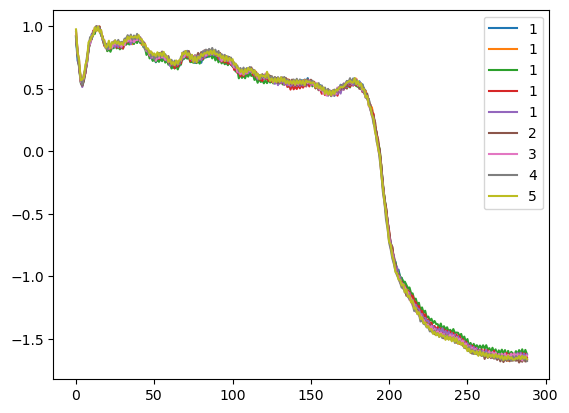

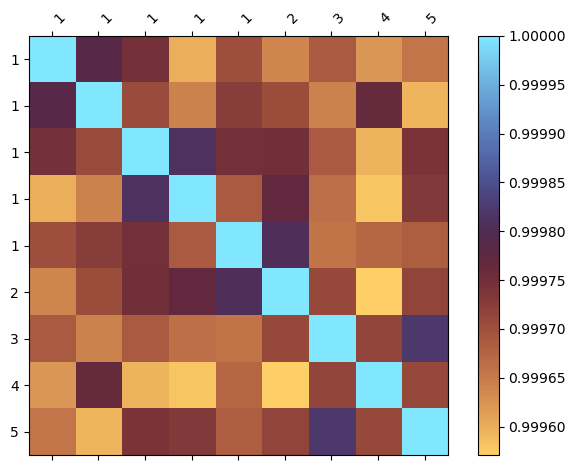

In [148]:
roi_map = {
    'tdp0604': (155, 445),
    'pi3hdx12211': (160, 450),
}
foo = list(roi_map.values())[0]
roi_n = foo[1] - foo[0]

def plot_covar(group_a, group_b, select_trace='open_fwd', select_channel='adc1', smooth=None):
    group_a = sorted(group_a, key=lambda entry: entry['info']['serial'])
    group_b = sorted(group_b, key=lambda entry: entry['info']['serial'])
    all_traces = group_a + group_b
        
    d = np.zeros((len(all_traces), roi_n))
    labels = []
    for i, trace in enumerate(all_traces):
        trace_data = trace['data'][select_trace][select_channel]
        start, end = roi_map[trace['info']['chip']]
        trace_data = trace_data[start:end]

        if smooth is not None:
            t = np.linspace(0, 1, len(trace_data))
            spl = interpolate.make_smoothing_spline(t, trace_data, lam=smooth)
            trace_data = spl(t)
        
        d[i] = trace_data
        labels.append(str(trace['info']['serial']))
        
    
    # Normalize each curve such that its mean is at 0 and its min is at -1
    deltas = d[:,1:]
    deltas -= np.repeat(deltas.mean(axis=1)[:,np.newaxis], roi_n-1, axis=1)
    deltas /= np.repeat(deltas.max(axis=1)[:,np.newaxis], roi_n-1, axis=1)
    
    # Align all curves such that the trace starts where the trace crosses 0.5
    #roi_refined = round(np.mean(roi_n - 1 - np.argmax(deltas[:,::-1] > 0.5, axis=1))), roi_n
    #deltas = deltas[:,roi_refined[0]:roi_refined[1]]
    
    corr = np.corrcoef(deltas)
    
    fig, ax = plt.subplots()
    for x, lab in zip(deltas, labels):
        ax.plot(x, label=lab)
    ax.legend()
    
    within_class = corr[:4, :4][np.triu_indices(4)]
    cross_class = corr[4:, :4].flatten()
    
    cdf = lambda x, mu, sigma: 1/2 * (1 + math.erf((x - mu) / (sigma * math.sqrt(2))))
    threshold = (np.mean(within_class) + np.mean(cross_class)) / 2
    print(f'Baseline threshold set at {threshold:.6f}')
    
    for name, data in [('Within', within_class), ('Cross', cross_class)]:
        print(f'{name} class: {np.mean(data):.3g}±{np.std(data):.3g} max: {np.max(data):.3g}')
    print(f'Baseline false negative probability: {cdf(threshold, np.mean(within_class), np.std(within_class)):.12f}')
    print(f'Baseline false positive probability: {1 - cdf(threshold, np.mean(cross_class), np.std(cross_class)):.12f}')
    
    #corr -= np.min(corr)
    #corr /= np.max(corr)
    
    #for i in range(len(corr[0])):
    #    corr[i, i] = math.nan
    
    fig, ax = plt.subplots()
    cax = ax.matshow(corr, interpolation='nearest', cmap='managua')
    fig.colorbar(cax)
    ax.set_xticks(list(range(len(labels))))
    ax.set_xticklabels(labels, rotation=45, ha='left')
    ax.set_yticks(list(range(len(labels))))
    ax.set_yticklabels(labels)
    fig.tight_layout()
    #fig.savefig('../paper/manip_pearson_corr.pdf')

#group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0001-0.4'][-5:]
#group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[23456]-0\.4', key)}.values())

group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and key == 'M-SP-PITCH-V2-0001-0.4'][-5:]
group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and re.match(r'M-SP-PITCH-V2-000[23456]-0\.4', key)}.values())
plot_covar(group_a, group_b, select_trace='open_fwd', select_channel='adc1', smooth=None)

Baseline threshold set at 0.904802
Within class: 0.929±0.0581 max: 1
Cross class: 0.88±0.0119 max: 0.901
Baseline false negative probability: 0.336223980515
Baseline false positive probability: 0.019732230444


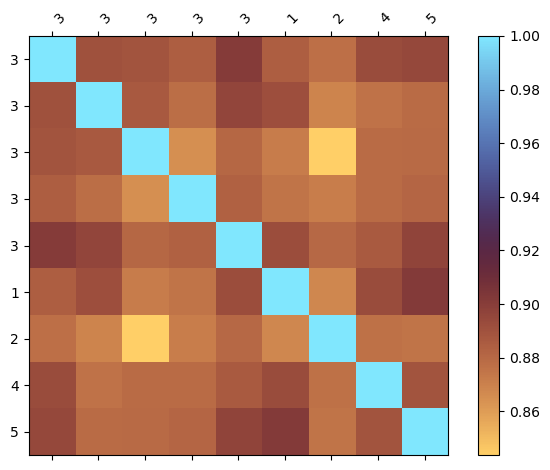

In [149]:
def plot_vector_covar(group_a, group_b, do_cal=False):
    group_a = sorted(group_a, key=lambda entry: entry['info']['serial'])
    group_b = sorted(group_b, key=lambda entry: entry['info']['serial'])
    all_traces = group_a + group_b
        
    d = np.zeros((len(all_traces), 12, roi_n))
    labels = []
    for i, entry in enumerate(all_traces):
        start, end = roi_map[entry['info']['chip']]
        labels.append(entry['info']['serial'])
        for j, (term, direction, channel) in enumerate(itertools.product(['open', 'short', 'load'], ['fwd', 'flip'], ['adc1', 'adc2'])):
            trace_data = np.array(entry['data'][f'{term}_{direction}'][channel])
            if do_cal:
                trace_data -= np.array(entry['data']['cal'][channel])
            d[i, j] = trace_data[start:end]
    
    # Normalize each curve such that its mean is at 0 and its min is at -1
    deltas = d[:,:,1:]
    deltas -= np.repeat(deltas.mean(axis=2)[:,:,np.newaxis], roi_n-1, axis=2)
    deltas /= np.repeat(deltas.max(axis=2)[:,:,np.newaxis], roi_n-1, axis=2)
    
    # Align all curves such that the trace starts where the trace crosses 0.5
    #roi_refined = round(np.mean(roi_n - 1 - np.argmax(deltas[:,::-1] > 0.5, axis=1))), roi_n
    #deltas = deltas[:,roi_refined[0]:roi_refined[1]]

    corr = np.zeros((12, len(all_traces), len(all_traces)))
    for i in range(12):
        corr[i] = np.corrcoef(deltas[:,i,:])
    corr = np.sqrt(np.min(np.square(corr), axis=0))
    
    within_class = corr[:4, :4][np.triu_indices(4)]
    cross_class = corr[4:, :4].flatten()
    
    cdf = lambda x, mu, sigma: 1/2 * (1 + math.erf((x - mu) / (sigma * math.sqrt(2))))
    threshold = (np.mean(within_class) + np.mean(cross_class)) / 2
    #threshold = np.mean(within_class) -2*np.std(within_class)
    #threshold = (np.mean(within_class) + np.max(cross_class)) / 2
    print(f'Baseline threshold set at {threshold:.6f}')
    
    for name, data in [('Within', within_class), ('Cross', cross_class)]:
        print(f'{name} class: {np.mean(data):.3g}±{np.std(data):.3g} max: {np.max(data):.3g}')
    print(f'Baseline false negative probability: {cdf(threshold, np.mean(within_class), np.std(within_class)):.12f}')
    print(f'Baseline false positive probability: {1 - cdf(threshold, np.mean(cross_class), np.std(cross_class)):.12f}')
    
    #corr -= np.min(corr)
    #corr /= np.max(corr)
    
    #for i in range(len(corr[0])):
    #    corr[i, i] = math.nan
    
    fig, ax = plt.subplots()
    cax = ax.matshow(corr, interpolation='nearest', cmap='managua')
    fig.colorbar(cax)
    ax.set_xticks(list(range(len(labels))))
    ax.set_xticklabels(labels, rotation=45, ha='left')
    ax.set_yticks(list(range(len(labels))))
    ax.set_yticklabels(labels)
    fig.tight_layout()
    #fig.savefig('../paper/manip_pearson_corr.pdf')

group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0003-0.4'][-5:]
group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[1245]-0\.4', key)}.values())
plot_vector_covar(group_a, group_b)

## Can we distinguish one specimen from other specimens with the same layout?

Baseline threshold set at 0.897614
Within class: 0.925±0.0618 max: 1
Cross class: 0.87±0.0158 max: 0.89
Baseline false negative probability: 0.328295699293
Baseline false positive probability: 0.040852922489


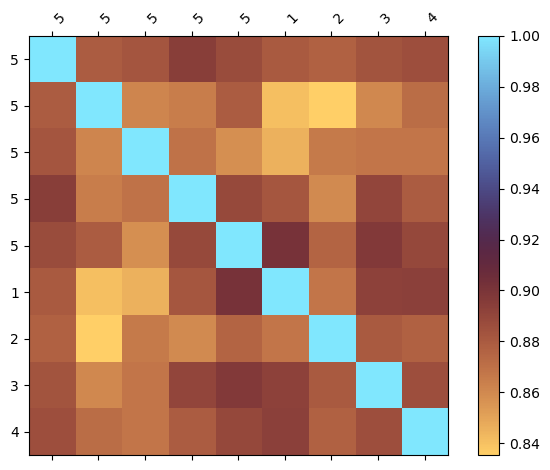

In [150]:
group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0005-0.4'][-5:]
group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[1234]-0\.4', key)}.values())
plot_vector_covar(group_a, group_b)

## Can we distinguish mesh layout variants?

Compare measurements of five specimens of the base layout against measurements of each of the four alternate layouts.

Baseline threshold set at 0.829567
Within class: 0.929±0.058 max: 1
Cross class: 0.73±0.11 max: 0.901
Baseline false negative probability: 0.042371611873
Baseline false positive probability: 0.182307330178


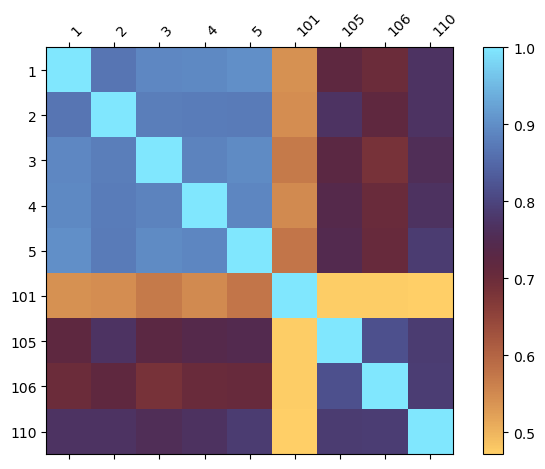

In [151]:
group_a = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[12345]-0\.4', key)}.values())
group_b = list({val['info']['mesh_layout']: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and 'ALT' in val['info']['mesh_layout']}.values())
plot_vector_covar(group_a, group_b)

#### Same measurement, but show TPD0604 data 

Baseline threshold set at 0.977581
Within class: 0.994±0.00492 max: 1
Cross class: 0.961±0.0478 max: 0.99
Baseline false negative probability: 0.000388241951
Baseline false positive probability: 0.364434589014


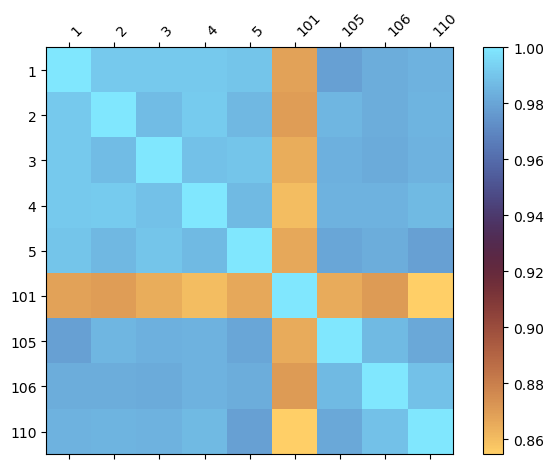

In [152]:
group_a = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and re.match(r'M-SP-PITCH-V2-000[12345]-0\.4', key)}.values())
group_b = list({val['info']['mesh_layout']: val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and 'ALT' in val['info']['mesh_layout']}.values())
plot_vector_covar(group_a, group_b, do_cal=False)

Baseline threshold set at 0.625063
Within class: 0.95±0.0422 max: 1
Cross class: 0.3±0.272 max: 0.927
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.116091029999


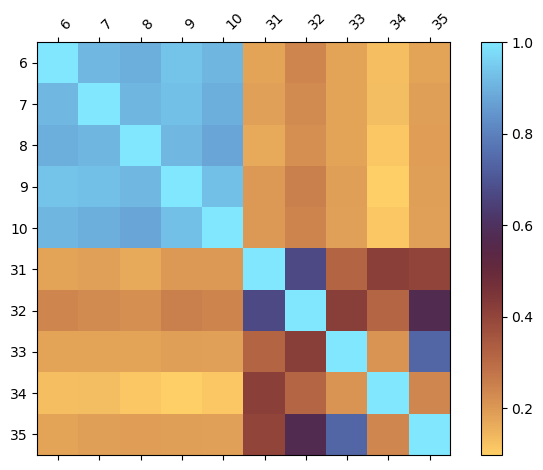

In [153]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_across_traces', 0.3])

Baseline threshold set at 0.622192
Within class: 0.95±0.0422 max: 1
Cross class: 0.295±0.273 max: 0.927
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.114950604339


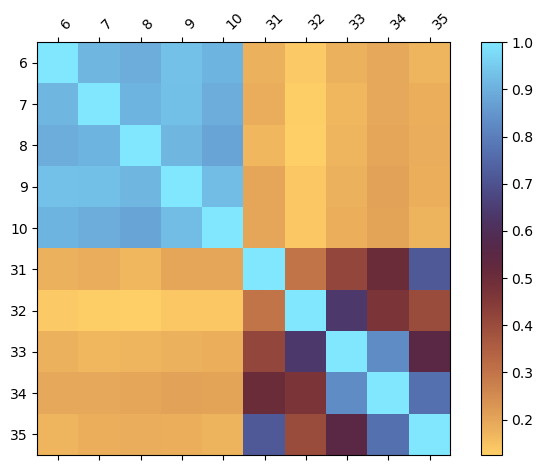

In [154]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_across_traces', 0.4])

Baseline threshold set at 0.600452
Within class: 0.95±0.0422 max: 1
Cross class: 0.251±0.297 max: 0.927
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.119458980091


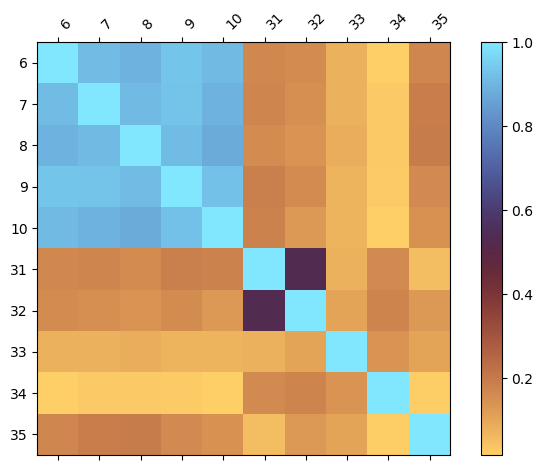

In [155]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_across_traces', 0.6])

Baseline threshold set at 0.588677
Within class: 0.95±0.0422 max: 1
Cross class: 0.228±0.304 max: 0.927
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.117165682708


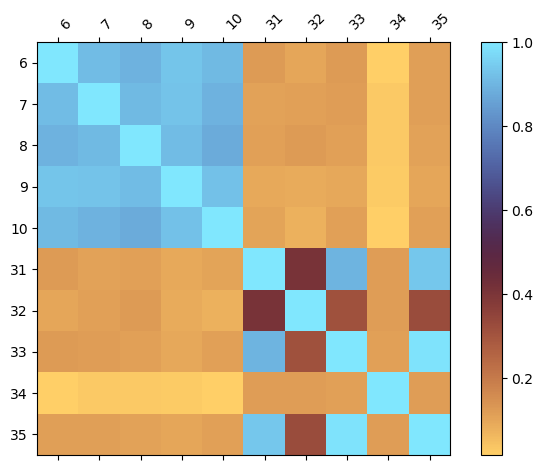

In [156]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_across_traces', 1.0])

Baseline threshold set at 0.591883
Within class: 0.95±0.0422 max: 1
Cross class: 0.234±0.306 max: 0.927
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.120789151555


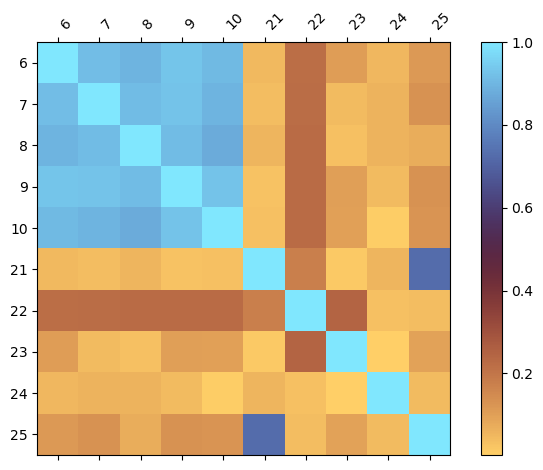

In [157]:
plot_vector_covar(mod_baseline[0.3], mod_modified['open', 0.3])

Baseline threshold set at 0.604316
Within class: 0.95±0.0422 max: 1
Cross class: 0.259±0.295 max: 0.927
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.120689459027


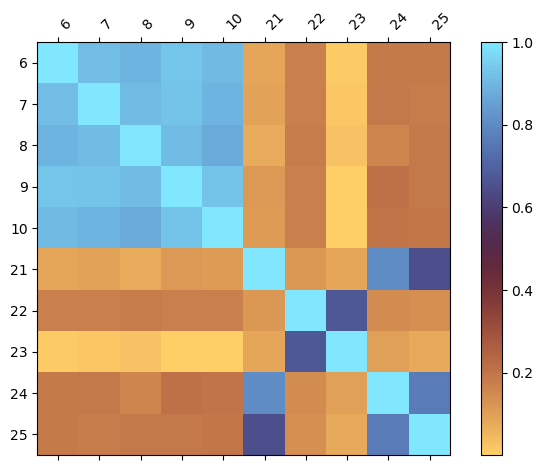

In [158]:
plot_vector_covar(mod_baseline[0.3], mod_modified['open', 0.4])

Baseline threshold set at 0.582005
Within class: 0.95±0.0422 max: 1
Cross class: 0.214±0.313 max: 0.927
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.120070867700


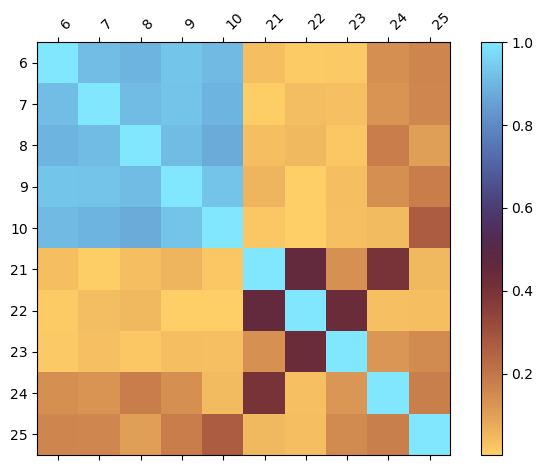

In [159]:
plot_vector_covar(mod_baseline[0.3], mod_modified['open', 0.6])

Baseline threshold set at 0.576966
Within class: 0.95±0.0422 max: 1
Cross class: 0.204±0.314 max: 0.927
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.117391521375


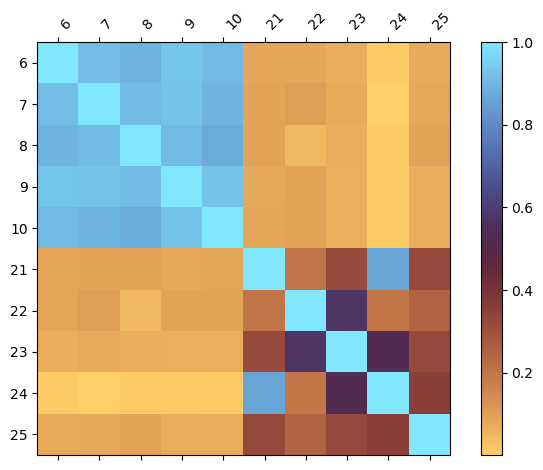

In [160]:
plot_vector_covar(mod_baseline[0.3], mod_modified['open', 1.0])

Baseline threshold set at 0.809155
Within class: 0.95±0.0422 max: 1
Cross class: 0.669±0.287 max: 0.927
Baseline false negative probability: 0.000436779327
Baseline false positive probability: 0.312142538985


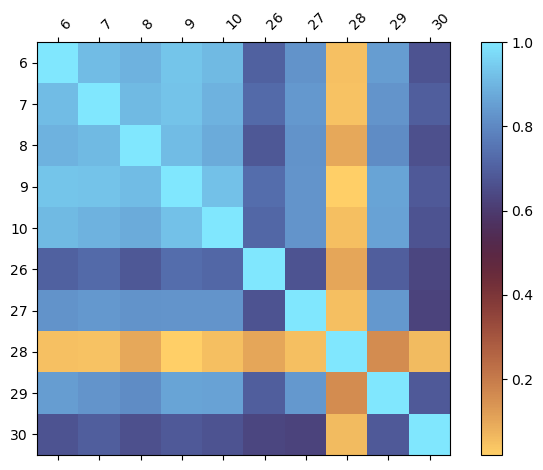

In [167]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_within_trace', 0.3])

Baseline threshold set at 0.687838
Within class: 0.95±0.0422 max: 1
Cross class: 0.426±0.238 max: 0.927
Baseline false negative probability: 0.000000000278
Baseline false positive probability: 0.135453892160


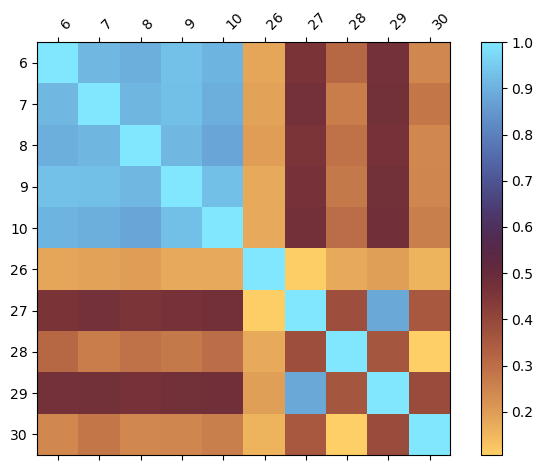

In [162]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_within_trace', 0.4])

Baseline threshold set at 0.577259
Within class: 0.95±0.0422 max: 1
Cross class: 0.205±0.315 max: 0.927
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.118607743353


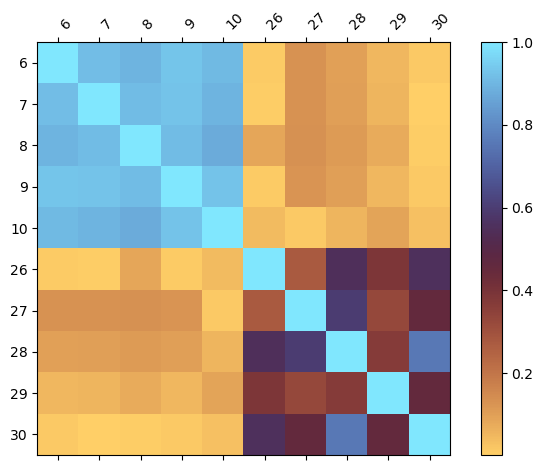

In [163]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_within_trace', 0.6])

Baseline threshold set at 0.571955
Within class: 0.95±0.0422 max: 1
Cross class: 0.194±0.318 max: 0.927
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.117397029948


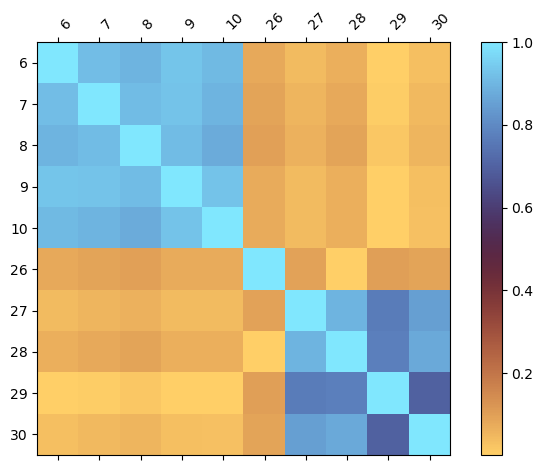

In [164]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_within_trace', 1.0])